In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Load Iris dataset
iris = load_iris()

# Create DataFrame
df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

# Add target column
df['target'] = iris.target

# Display first five rows
print("First Five Rows:")
display(df.head())

# Dataset information
print("\nDataset Information:")
print(df.info())

# Statistical summary
print("\nStatistical Summary:")
display(df.describe())

First Five Rows:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB
None

Statistical Summary:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


In [3]:
# Dataset shape
print("Dataset Shape:", df.shape)

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check class distribution
print("\nClass Distribution:")
print(df['target'].value_counts())

# Display class names
print("\nTarget Class Names:")
print(iris.target_names)

Dataset Shape: (150, 5)

Missing Values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
dtype: int64

Class Distribution:
target
0    50
1    50
2    50
Name: count, dtype: int64

Target Class Names:
['setosa' 'versicolor' 'virginica']


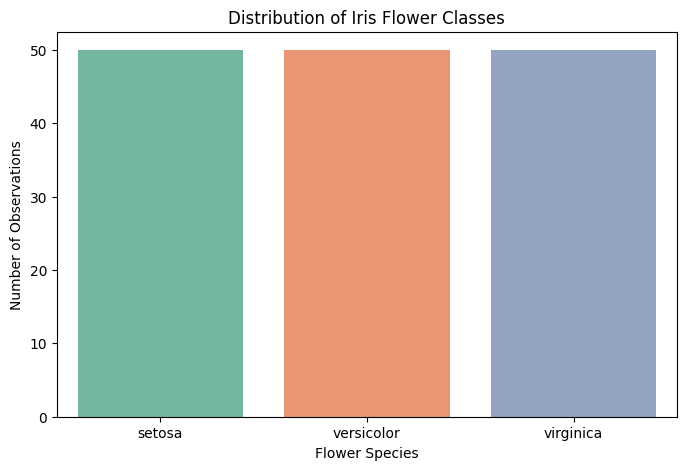

In [4]:
plt.figure(figsize=(8, 5))

sns.countplot(
    x=df['target'],
    hue=df['target'],
    palette='Set2',
    legend=False
)

plt.xticks(
    [0, 1, 2],
    iris.target_names
)

plt.title("Distribution of Iris Flower Classes")
plt.xlabel("Flower Species")
plt.ylabel("Number of Observations")

plt.show()

In [5]:
# Separate features and target
X = df.drop('target', axis=1)
y = df['target']

print("Independent Variables:")
display(X.head())

print("\nDependent Variable:")
print(y.head())

print("\nFeatures Shape:", X.shape)
print("Target Shape:", y.shape)

Independent Variables:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2



Dependent Variable:
0    0
1    0
2    0
3    0
4    0
Name: target, dtype: int64

Features Shape: (150, 4)
Target Shape: (150,)


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("\nData Splitting Completed Successfully!")

Training Data Shape: (120, 4)
Testing Data Shape: (30, 4)

Data Splitting Completed Successfully!


In [7]:
# Create Decision Tree Classifier
model = DecisionTreeClassifier(
    criterion='gini',
    max_depth=3,
    random_state=42
)

# Train the model
model.fit(X_train, y_train)

print("Decision Tree Model Trained Successfully!")

Decision Tree Model Trained Successfully!


In [8]:
# Predict test data
y_pred = model.predict(X_test)

print("Actual Values:")
print(y_test.values[:10])

print("\nPredicted Values:")
print(y_pred[:10])

print("\nPredictions Completed Successfully!")

Actual Values:
[0 2 1 1 0 1 0 0 2 1]

Predicted Values:
[0 2 1 1 0 1 0 0 2 1]

Predictions Completed Successfully!


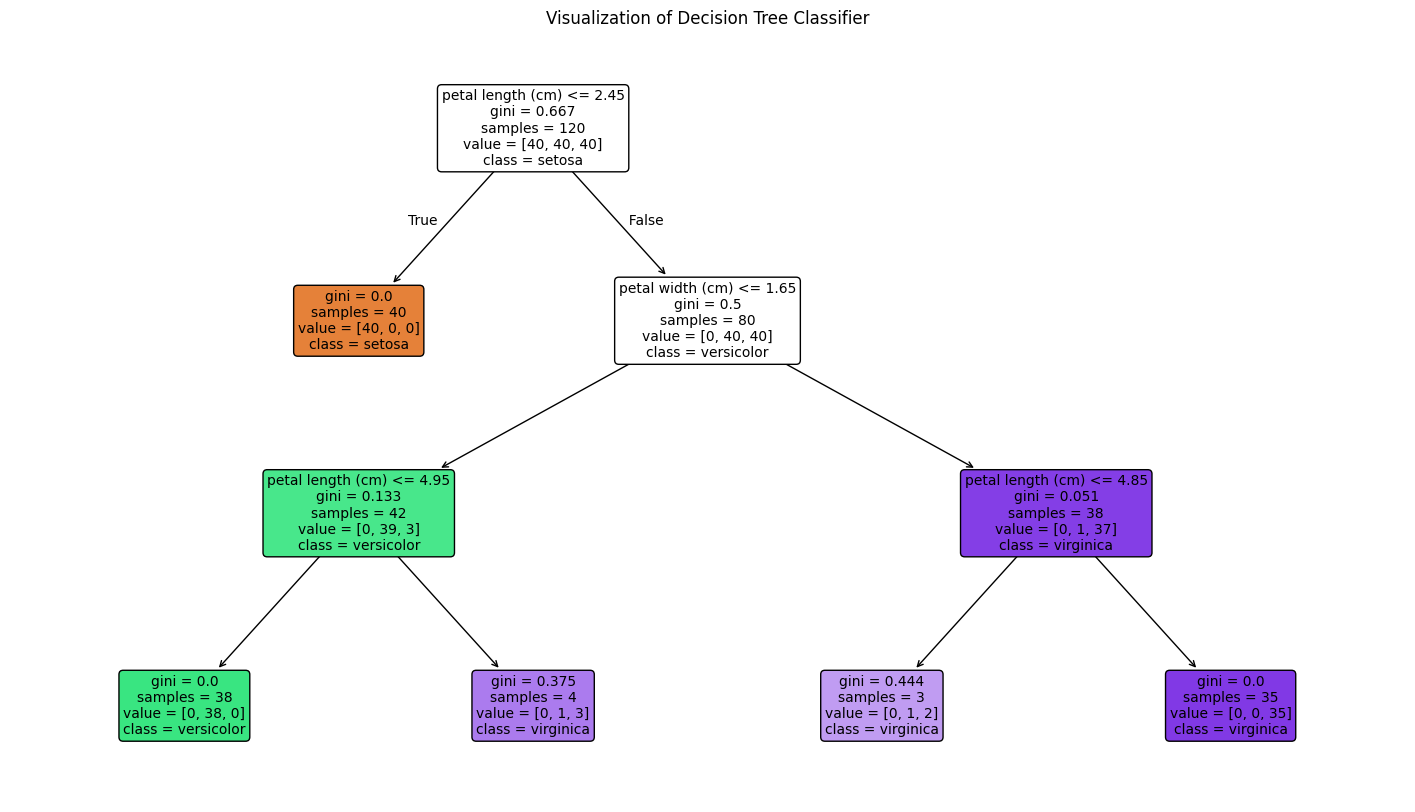

In [9]:
plt.figure(figsize=(18, 10))

plot_tree(
    model,
    feature_names=iris.feature_names,
    class_names=iris.target_names,
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title("Visualization of Decision Tree Classifier")

plt.show()

In [10]:
# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Decision Tree Model Accuracy:")
print("-----------------------------")

print("Accuracy:", round(accuracy, 4))

print("Accuracy Percentage:",
      round(accuracy * 100, 2), "%")

Decision Tree Model Accuracy:
-----------------------------
Accuracy: 0.9667
Accuracy Percentage: 96.67 %


Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]


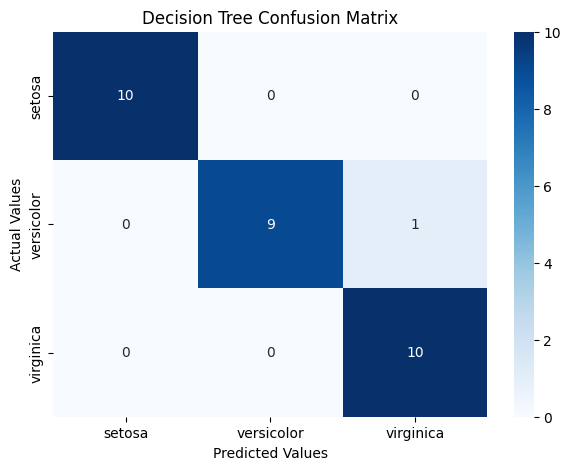

In [11]:
# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

# Visualize confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")

plt.title("Decision Tree Confusion Matrix")

plt.show()

In [12]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Calculate evaluation metrics
precision = precision_score(
    y_test, y_pred, average='weighted'
)

recall = recall_score(
    y_test, y_pred, average='weighted'
)

f1 = f1_score(
    y_test, y_pred, average='weighted'
)

print("Model Evaluation Results")
print("------------------------")

print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1-Score:", round(f1, 4))

Model Evaluation Results
------------------------
Precision: 0.9697
Recall: 0.9667
F1-Score: 0.9666


In [13]:
print("Classification Report:")
print("----------------------")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=iris.target_names
    )
)

Classification Report:
----------------------
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



Feature Importance:


,Feature,Importance
2,petal length (cm),0.579077
3,petal width (cm),0.420923
1,sepal width (cm),0.000000
0,sepal length (cm),0.000000


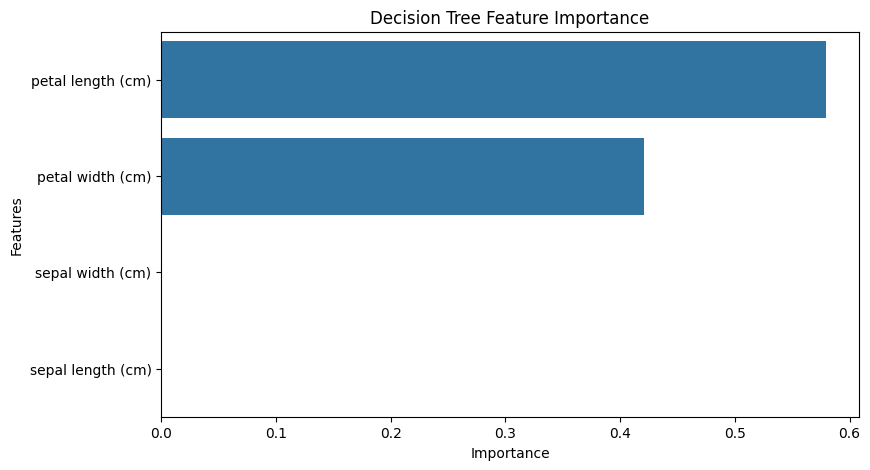

In [14]:
# Get feature importance
importance = model.feature_importances_

# Create DataFrame
feature_importance = pd.DataFrame({
    'Feature': iris.feature_names,
    'Importance': importance
})

# Sort in descending order
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print("Feature Importance:")
display(feature_importance)

# Visualize feature importance
plt.figure(figsize=(9, 5))

sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature'
)

plt.title("Decision Tree Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Features")

plt.show()

In [15]:
# Calculate training accuracy
train_accuracy = model.score(X_train, y_train)

# Calculate testing accuracy
test_accuracy = model.score(X_test, y_test)

print("Training Accuracy:",
      round(train_accuracy * 100, 2), "%")

print("Testing Accuracy:",
      round(test_accuracy * 100, 2), "%")

if train_accuracy - test_accuracy > 0.15:
    print("The model may be overfitting.")
else:
    print("No large training-testing accuracy gap detected.")

Training Accuracy: 98.33 %
Testing Accuracy: 96.67 %
No large training-testing accuracy gap detected.


In [16]:
print("FINAL RESULT")
print("============")

print("Algorithm: Decision Tree Classifier")
print("Dataset: Iris Dataset")
print("Number of Features:", X.shape[1])
print("Number of Classes:", len(iris.target_names))

print("\nModel Performance:")
print("Accuracy:", round(accuracy * 100, 2), "%")
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1-Score:", round(f1, 4))

print("\nDecision Tree Visualization Generated.")
print("Model trained and evaluated successfully!")
print("Experiment Completed Successfully!")

FINAL RESULT
Algorithm: Decision Tree Classifier
Dataset: Iris Dataset
Number of Features: 4
Number of Classes: 3

Model Performance:
Accuracy: 96.67 %
Precision: 0.9697
Recall: 0.9667
F1-Score: 0.9666

Decision Tree Visualization Generated.
Model trained and evaluated successfully!
Experiment Completed Successfully!
